# Model development

This notebook builds the model that predicts whether a customer subscribes to a term deposit (`y`). On the training set, it starts with a LazyPredict screen, then compares four models with and without class-imbalance fixes, tunes them, and chooses a decision threshold for the best one. The final model is then scored once on the test set and saved to `models/`.

In [1]:
import sys
from pathlib import Path

project_root = Path.cwd().parents[1]
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

In [2]:
import joblib
import matplotlib.pyplot as plt
import pandas as pd
from lazypredict.Supervised import CLASSIFIERS, LazyClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split

from src.data.load_data import load_raw_data, split_features_target
from src.models.evaluate import (
    call_outcomes,
    cv_summary,
    gains_table,
    score_models,
    threshold_table,
)
from src.models.train import (
    build_models,
    build_pipeline,
    save_model,
    tune_model,
    tune_threshold,
)
from src.utils.config import (
    CV_FOLDS,
    FIGURES_DIR,
    FINAL_MODEL_PATH,
    RANDOM_STATE,
    TARGET_ACCURACY,
    TEST_SIZE,
    VALIDATION_SIZE,
)

## Train/test split

In [3]:
df = load_raw_data()
X, y = split_features_target(df)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

X_train.shape, X_test.shape, y_train.mean().round(3), y_test.mean().round(3)

((32000, 13), (8000, 13), np.float64(0.072), np.float64(0.072))

The data is split into 32,000 training customers and 8,000 test customers. The rows are in time order, and `train_test_split` shuffles them before splitting. Without the shuffle, the test set would be the last 8,000 rows from the most recent months. The split is also stratified on `y`, which keeps the subscription rate at 7.2% in both sets. Cross-validation runs on the training set only. The test set is scored once, after the final model is chosen.

## Preprocessing

In [4]:
categorical_cols = X_train.select_dtypes(include="str").columns.tolist()
numeric_cols = X_train.select_dtypes(include="number").columns.tolist()

categorical_cols, numeric_cols

(['job',
  'marital',
  'education',
  'default',
  'housing',
  'loan',
  'contact',
  'month'],
 ['age', 'balance', 'day', 'duration', 'campaign'])

The 8 categorical columns are one-hot encoded, and the 5 numeric columns are scaled to a mean of 0 and a standard deviation of 1. `build_preprocessor` in `src/models/train.py` does both. Scaling only affects logistic regression and SMOTE, which measures distances between rows. The tree models give the same predictions with or without it, so one preprocessor is used for every model.

`build_pipeline` puts the preprocessing in front of each model. Cross-validation refits the whole pipeline on the training part of every fold, so the validation part never influences the encoding or scaling.

## Cross-validation setup

In [5]:
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

Cross-validation uses 5 folds of the training set, and each cross-validation score below is the average over the 5 held-out folds. The folds are stratified, so each one keeps the 7.2% subscription rate. They are also shuffled, because unshuffled folds would each cover a block of consecutive months. Every cross-validated model below uses these same folds, so their scores can be compared directly.

## Baseline

Every model is scored on six metrics, defined in `SCORING` in `src/models/evaluate.py`. Accuracy, precision, recall, and F1 depend on the decision threshold that turns a model's score into "yes" or "no", which is 0.5 by default. PR-AUC and ROC-AUC measure how well a model ranks subscribers above non-subscribers, without choosing a threshold. PR-AUC is the main comparison metric because it focuses on the top of that ranking, the customers who would be called. A model that ranks customers at random scores about 0.072 on PR-AUC (the subscription rate) and 0.5 on ROC-AUC.

Precision and recall describe the calls a model would make. A true positive is a call that reaches a subscriber, a false positive is an unnecessary call, and a false negative is a subscriber who never gets a call.

- Precision is the share of calls made that reach a subscriber. Low precision means more unnecessary calls, which waste call center agents' time.
- Recall is the share of all subscribers who get a call. Low recall means more missed subscribers.

Every subscriber is either a true positive or a false negative, so maximizing true positives and minimizing false negatives are the same goal, and both mean higher recall. Recall cannot be the only goal, though. Calling everyone would find every subscriber, and only 7.2% of those calls would reach one. A missed subscriber is a lost sale, and an unnecessary call costs an agent a few minutes, so recall comes first, and precision is tracked to keep the number of calls reasonable.

In [6]:
cv_summary(DummyClassifier(strategy="most_frequent"), X_train, y_train, cv).round(3)

accuracy     0.928
precision    0.000
recall       0.000
f1           0.000
pr_auc       0.072
roc_auc      0.500
dtype: float64

Always predicting "no" scores 92.8% accuracy, above the 81% target, and finds zero subscribers. Precision, recall, and F1 are all 0, and PR-AUC (0.072) and ROC-AUC (0.5) are at the no-skill floor. Accuracy cannot tell this model apart from a useful one, so the models below are compared mainly on PR-AUC.

## LazyPredict screen

LazyPredict fits the classifiers in its default list from scikit-learn and XGBoost, except the two skipped below, on 80% of the training set with default settings. Any model that fails to run is left out of the table. `score_models` then scores each fitted model on the other 20% with the six metrics used for the baseline, and the table is sorted by PR-AUC.

`time_taken` is the number of seconds each model took to train and score, and it is the only column taken from LazyPredict's own results table. That table has no PR-AUC, and its precision, recall, and F1 are averaged over both classes, so the "no" class dominates them. The models have no class weights and the scores come from one validation split, so the ranking is a rough guide.

In [7]:
X_fit, X_valid, y_fit, y_valid = train_test_split(
    X_train,
    y_train,
    test_size=VALIDATION_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_train,
)

# Label propagation and label spreading take minutes each, so they are skipped.
skipped = ["LabelPropagation", "LabelSpreading"]
lazy = LazyClassifier(
    classifiers=[model for name, model in CLASSIFIERS if name not in skipped],
    random_state=RANDOM_STATE,
)
lazy_results, _ = lazy.fit(X_fit, X_valid, y_fit, y_valid)
lazy_models = lazy.provide_models(X_fit, X_valid, y_fit, y_valid)

lazy_scores = score_models(lazy_models, X_valid, y_valid)
lazy_scores["time_taken"] = lazy_results["Time Taken"]
lazy_scores.sort_values("pr_auc", ascending=False).round(3)

,accuracy,precision,recall,f1,pr_auc,roc_auc,time_taken
LogisticRegression,0.939,0.691,0.289,0.408,0.562,0.938,0.438
CalibratedClassifierCV,0.938,0.660,0.294,0.407,0.559,0.939,1.161
LinearSVC,0.937,0.759,0.190,0.304,0.558,0.939,0.390
RandomForestClassifier,0.936,0.633,0.283,0.391,0.551,0.942,5.048
XGBClassifier,0.936,0.580,0.421,0.488,0.549,0.946,1.113
RidgeClassifier,0.934,0.722,0.140,0.235,0.545,0.936,0.447
RidgeClassifierCV,0.934,0.722,0.140,0.235,0.545,0.936,0.604
LinearDiscriminantAnalysis,0.938,0.587,0.475,0.525,0.544,0.936,0.428
NearestCentroid,0.872,0.326,0.715,0.448,0.539,0.929,0.295
SVC,0.932,0.704,0.108,0.187,0.539,0.909,25.631


- The five models with the highest PR-AUC are LogisticRegression (0.562), CalibratedClassifierCV (0.559), LinearSVC (0.558), RandomForestClassifier (0.551), and XGBClassifier (0.549). The same five have the highest ROC-AUC, in a different order. Three are linear models (CalibratedClassifierCV wraps a LinearSVC by default), and two are tree ensembles. LogisticRegression is the only linear model tested below, since CalibratedClassifierCV and LinearSVC scored within 0.004 of it on PR-AUC. RandomForestClassifier and XGBClassifier are also tested below, along with HistGradientBoostingClassifier, which is not in LazyPredict's default list.
- The top 10 models are within 0.023 of each other on PR-AUC (0.539 to 0.562), and each one scores 7.5 to 7.8 times the no-skill 0.072. Differences that small could reverse with a different validation split, so this screen cannot pick a single best model.
- Precision and recall depend on each model's default threshold, a 0.5 probability for models that output probabilities. LinearSVC and XGBClassifier have almost the same PR-AUC (0.558 and 0.549), but LinearSVC's recall is 0.190 and XGBClassifier's is 0.421. The two models rank customers about equally well, and their default thresholds fall at different points in those rankings. The threshold can be changed after training, so the models are compared on PR-AUC here.

## Class weights

Four models are cross-validated on the folds above. Logistic regression, random forest, and XGBoost were in LazyPredict's top five. Hist gradient boosting is not in LazyPredict's list. It is scikit-learn's own gradient boosting model, added as a check on XGBoost.

Each model is cross-validated twice, without and with class weights. Class weights make each "yes" row count more during training. With `class_weight="balanced"`, the "yes" rows carry the same total weight as the "no" rows, even though they are only 7.2% of the data. XGBoost has no `class_weight` option, so `scale_pos_weight` multiplies the weight of every "yes" row by the ratio of "no" rows to "yes" rows, which gives the same balance.

In [8]:
cv_results = {}
for class_weighted in [False, True]:
    imbalance_fix = "class weights" if class_weighted else "no fix"
    for name, model in build_models(y_train, class_weighted=class_weighted).items():
        pipeline = build_pipeline(model, categorical_cols, numeric_cols)
        cv_results[name, imbalance_fix] = cv_summary(pipeline, X_train, y_train, cv)

cv_table = pd.DataFrame.from_dict(cv_results, orient="index")
cv_table.index.names = ["model", "imbalance_fix"]
cv_table.sort_index(level="model", sort_remaining=False).round(3)

accuracy  precision  recall     f1  \
model                  imbalance_fix                                       
Hist gradient boosting no fix            0.937      0.595   0.407  0.482   
                       class weights     0.881      0.367   0.897  0.521   
Logistic regression    no fix            0.934      0.602   0.274  0.375   
                       class weights     0.869      0.340   0.864  0.488   
Random forest          no fix            0.936      0.613   0.308  0.408   
                       class weights     0.928      0.505   0.579  0.539   
XGBoost                no fix            0.935      0.573   0.423  0.486   
                       class weights     0.910      0.430   0.759  0.549   

                                      pr_auc  roc_auc  
model                  imbalance_fix                   
Hist gradient boosting no fix          0.547    0.949  
                       class weights   0.542    0.948  
Logistic regression    no fix          0.493    0.928  
                       class weights   0.490    0.932  
Random forest          no fix          0.526    0.939  
                       class weights   0.514    0.942  
XGBoost                no fix          0.531    0.945  
                       class weights   0.522    0.940

- With class weights, recall rises and precision falls for all four models. Logistic regression's recall rises the most, from 0.274 to 0.864, and random forest's rises the least, from 0.308 to 0.579.
- PR-AUC falls slightly for all four models with class weights, by 0.003 (logistic regression) to 0.012 (random forest). ROC-AUC changes by 0.005 or less, up for logistic regression and random forest and down for hist gradient boosting and XGBoost. Class weights push the scores for "yes" upward, so more customers clear the 0.5 threshold. The order of the customers barely changes, and PR-AUC and ROC-AUC only measure that order.
- Since the ranking barely changes, a lower threshold on the no-fix models could give the same recall as class weights. The decision threshold section below tests this.
- Random forest's recall rises the least because its trees keep splitting until every leaf holds a single class. A leaf that holds only "no" rows predicts "no" whatever the class weights are, so the weights can only change where the trees split. Tuning `min_samples_leaf` below allows leaves with both classes, where the weights affect the prediction.
- LazyPredict scored logistic regression at 0.562 PR-AUC on one validation split, and cross-validation gives 0.493. One split can be easier or harder than average, and cross-validation scores every training row once, so cross-validation gives the more reliable comparison.
- Every model stays above the 81% accuracy target with and without class weights. The lowest is logistic regression with class weights, at 0.869.

## SMOTE

SMOTE (Synthetic Minority Over-sampling Technique) is the other common fix for class imbalance. It adds new "yes" rows instead of weighting the existing ones. Each new row is placed at a random point on the line between a real "yes" row and one of its 5 nearest "yes" neighbors, and rows are added until both classes are the same size. The four models run without class weights here, since SMOTE already balances the classes.

SMOTE needs numeric columns, so it runs after the one-hot encoding and scaling. It runs inside the pipeline, so it only adds rows to the training part of each fold, and the validation part is scored on real customers only.

The table below adds the SMOTE results to the results from the class weights section.

In [9]:
for name, model in build_models(y_train, class_weighted=False).items():
    pipeline = build_pipeline(model, categorical_cols, numeric_cols, smote=True)
    cv_results[name, "SMOTE"] = cv_summary(pipeline, X_train, y_train, cv)

cv_table = pd.DataFrame.from_dict(cv_results, orient="index")
cv_table.index.names = ["model", "imbalance_fix"]
cv_table.sort_index(level="model", sort_remaining=False).round(3)

accuracy  precision  recall     f1  \
model                  imbalance_fix                                       
Hist gradient boosting no fix            0.937      0.595   0.407  0.482   
                       class weights     0.881      0.367   0.897  0.521   
                       SMOTE             0.928      0.504   0.644  0.565   
Logistic regression    no fix            0.934      0.602   0.274  0.375   
                       class weights     0.869      0.340   0.864  0.488   
                       SMOTE             0.872      0.345   0.853  0.491   
Random forest          no fix            0.936      0.613   0.308  0.408   
                       class weights     0.928      0.505   0.579  0.539   
                       SMOTE             0.928      0.502   0.513  0.507   
XGBoost                no fix            0.935      0.573   0.423  0.486   
                       class weights     0.910      0.430   0.759  0.549   
                       SMOTE             0.933      0.540   0.489  0.513   

                                      pr_auc  roc_auc  
model                  imbalance_fix                   
Hist gradient boosting no fix          0.547    0.949  
                       class weights   0.542    0.948  
                       SMOTE           0.530    0.947  
Logistic regression    no fix          0.493    0.928  
                       class weights   0.490    0.932  
                       SMOTE           0.490    0.930  
Random forest          no fix          0.526    0.939  
                       class weights   0.514    0.942  
                       SMOTE           0.488    0.940  
XGBoost                no fix          0.531    0.945  
                       class weights   0.522    0.940  
                       SMOTE           0.523    0.942

- SMOTE raises recall above no fix for all four models, but less than class weights do. The gap is small for logistic regression (0.853 vs. 0.864) and large for XGBoost (0.489 vs. 0.759).
- SMOTE lowers precision below no fix for all four models. Its precision is close to that of class weights for logistic regression and random forest, and higher for hist gradient boosting (0.504 vs. 0.367) and XGBoost (0.540 vs. 0.430).
- SMOTE lowers PR-AUC below no fix for all four models, by 0.003 (logistic regression) to 0.038 (random forest). Compared with class weights, it is lower for hist gradient boosting and random forest, the same for logistic regression, and 0.001 higher for XGBoost. Like class weights, SMOTE moves more customers past the 0.5 threshold without ranking them any better.
- SMOTE adds "yes" rows until they match the "no" rows. Since "yes" is only 7.2% of the data, about 92% of the "yes" rows each model trains on are new rows from SMOTE. A one-hot column is 0 or 1 for a real customer, but a new row between a retired customer and a technician gets values between 0 and 1 in both job columns, which describes no real customer. The models learn partly from customers that cannot exist, which may be why SMOTE ranks customers no better than no fix. SMOTENC, a version of SMOTE for categorical columns, gives new rows real categories instead, and was not tested here.
- Class weights are carried into tuning. They give the highest recall at the 0.5 threshold for every model, their PR-AUC is as high as or higher than SMOTE's for three of the four models, and they add no extra rows or pipeline step. No fix has a slightly higher PR-AUC than class weights for every model, so the decision threshold section compares the two.

## Hyperparameter tuning

Each class-weighted model is tuned with a randomized search over the ranges in `PARAM_DISTRIBUTIONS` in `src/models/train.py`. A randomized search covers wide ranges with fewer fits than a grid search. The ranges include each model's main settings for how closely it fits the training data, such as tree depth, leaf size, and learning rate. The search tries 20 random combinations per model, cross-validates each one on the folds above, and keeps the combination with the highest PR-AUC.

The tuned scores are slightly optimistic, because the same folds that chose the settings also score them. The test set gives the unbiased check at the end.

In [10]:
searches = {}
for name, model in build_models(y_train, class_weighted=True).items():
    pipeline = build_pipeline(model, categorical_cols, numeric_cols)
    searches[name] = tune_model(name, pipeline, X_train, y_train, cv)

In [11]:
pd.concat(
    {
        name: pd.Series(search.best_params_, dtype=object)
        for name, search in searches.items()
    }
)

Logistic regression     model__C                    56.698495
Random forest           model__min_samples_leaf             5
                        model__max_features               0.5
                        model__max_depth                   20
Hist gradient boosting  model__l2_regularization     3.603378
                        model__learning_rate         0.146955
                        model__max_iter                   400
                        model__max_leaf_nodes              15
                        model__min_samples_leaf            10
XGBoost                 model__colsample_bytree           0.6
                        model__learning_rate          0.00947
                        model__max_depth                    6
                        model__min_child_weight            10
                        model__n_estimators              1600
                        model__subsample                  0.5
dtype: object

In [12]:
tuned_results = {
    name: cv_summary(search.best_estimator_, X_train, y_train, cv)
    for name, search in searches.items()
}
tuned_table = pd.DataFrame.from_dict(tuned_results, orient="index")
tuned_table.round(3)

,accuracy,precision,recall,f1,pr_auc,roc_auc
Logistic regression,0.869,0.341,0.864,0.488,0.490,0.932
Random forest,0.900,0.409,0.855,0.553,0.537,0.947
Hist gradient boosting,0.876,0.360,0.908,0.516,0.546,0.948
XGBoost,0.891,0.389,0.871,0.537,0.553,0.949


- Tuning raised PR-AUC for three of the four models. XGBoost gained the most (0.522 to 0.553), then random forest (0.514 to 0.537) and hist gradient boosting (0.542 to 0.546). Logistic regression stayed at 0.490. Its only tuned setting is `C`, and the chosen value gives the same PR-AUC as the default.
- Random forest's recall rose from 0.579 to 0.855, and its precision fell from 0.505 to 0.409. Its chosen `min_samples_leaf` is 5. With the default of 1, every leaf holds a single class, and an all-"no" leaf predicts "no" whatever the class weights are. With at least 5 rows per leaf, many leaves hold both classes, and the class weights raise the "yes" score in those leaves.
- XGBoost has the highest PR-AUC (0.553), 0.007 above hist gradient boosting (0.546). The LazyPredict screen could not separate models within 0.023 of each other, so this gap is too small to call XGBoost clearly better. XGBoost is carried forward because it has the highest PR-AUC, and hist gradient boosting would be a reasonable alternative.
- Some chosen settings sit at the edge of their ranges in `PARAM_DISTRIBUTIONS`. For XGBoost, `n_estimators` is 1600 (the largest option), `subsample` is 0.5 (the smallest), and the learning rate (0.00947) is near the bottom of its range. For hist gradient boosting, `max_leaf_nodes` is 15 (the smallest). A setting at the edge suggests a better value might lie outside the range. Only 20 combinations were tried, so whether wider ranges would help is untested.
- Every tuned model stays above the 81% accuracy target. The lowest is logistic regression at 0.869.

## Decision threshold

The tuned model with the highest PR-AUC is carried forward, and its decision threshold is chosen by `tune_threshold` in `src/models/train.py`. It uses scikit-learn's `TunedThresholdClassifierCV`, which trains the model on 4 folds at a time, scores the held-out fold at 100 thresholds, and picks the threshold with the highest average F2 score across the 5 folds.

F2 is the F-beta score with a beta of 2, set by `THRESHOLD_BETA` in `src/utils/config.py`. It counts recall twice as much as precision. That matches the baseline section, where recall comes first and precision keeps the number of calls reasonable.

The class weights section suggested that a lower threshold might do the same job as class weights. To test this, the same tuned settings are also trained without class weights ("no fix"), and each version gets its own threshold. The settings were tuned with class weights, which may give that version a small advantage.

In [13]:
best_name = tuned_table["pr_auc"].idxmax()
no_fix = build_pipeline(
    build_models(y_train, class_weighted=False)[best_name],
    categorical_cols,
    numeric_cols,
)
candidates = {
    "class weights": searches[best_name].best_estimator_,
    "no fix": no_fix.set_params(**searches[best_name].best_params_),
}

In [14]:
threshold_models = {}
y_scores = {}
for label, model in candidates.items():
    threshold_models[label] = tune_threshold(model, X_train, y_train, cv)
    y_scores[label] = cross_val_predict(
        model, X_train, y_train, cv=cv, method="predict_proba"
    )[:, 1]

The first table shows the class-weighted model's calls at 7 thresholds, and the second shows the no-fix version's calls at the same thresholds. Both use out-of-fold predictions, where each customer is scored by the model trained on the other 4 folds. A lower threshold calls more customers, so it finds more subscribers and also makes more unnecessary calls.

In [15]:
thresholds = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
threshold_table(y_train, y_scores["class weights"], thresholds).round(1)

,calls made,calls made (% of customers),subscribers found,subscribers found (% of subscribers),subscribers missed,subscribers missed (% of subscribers),unnecessary calls,unnecessary calls (% of non-subscribers),unnecessary calls avoided,unnecessary calls avoided (% of non-subscribers),calls reaching a subscriber (% of calls made)
threshold,,,,,,,,,,,
0.2,7863,24.6,2232,96.3,85,3.7,5631,19.0,24052,81.0,28.4
0.3,6681,20.9,2183,94.2,134,5.8,4498,15.2,25185,84.8,32.7
0.4,5850,18.3,2097,90.5,220,9.5,3753,12.6,25930,87.4,35.8
0.5,5194,16.2,2018,87.1,299,12.9,3176,10.7,26507,89.3,38.9
0.6,4540,14.2,1921,82.9,396,17.1,2619,8.8,27064,91.2,42.3
0.7,3809,11.9,1784,77.0,533,23.0,2025,6.8,27658,93.2,46.8
0.8,2908,9.1,1513,65.3,804,34.7,1395,4.7,28288,95.3,52.0


In [16]:
threshold_table(y_train, y_scores["no fix"], thresholds).round(1)

,calls made,calls made (% of customers),subscribers found,subscribers found (% of subscribers),subscribers missed,subscribers missed (% of subscribers),unnecessary calls,unnecessary calls (% of non-subscribers),unnecessary calls avoided,unnecessary calls avoided (% of non-subscribers),calls reaching a subscriber (% of calls made)
threshold,,,,,,,,,,,
0.2,3824,12.0,1764,76.1,553,23.9,2060,6.9,27623,93.1,46.1
0.3,2847,8.9,1478,63.8,839,36.2,1369,4.6,28314,95.4,51.9
0.4,2083,6.5,1162,50.2,1155,49.8,921,3.1,28762,96.9,55.8
0.5,1435,4.5,863,37.2,1454,62.8,572,1.9,29111,98.1,60.1
0.6,840,2.6,543,23.4,1774,76.6,297,1.0,29386,99.0,64.6
0.7,356,1.1,239,10.3,2078,89.7,117,0.4,29566,99.6,67.1
0.8,90,0.3,62,2.7,2255,97.3,28,0.1,29655,99.9,68.9


The two tables below compare the class-weighted model with the no-fix version, each at its own threshold. The first shows each threshold and its F2 score, and the second shows the calls each one makes.

In [17]:
chosen = {
    label: {"threshold": tuned.best_threshold_, "f2": tuned.best_score_}
    for label, tuned in threshold_models.items()
}
pd.DataFrame.from_dict(chosen, orient="index").round(3)

,threshold,f2
class weights,0.493,0.699
no fix,0.118,0.687


In [18]:
calls = {
    label: call_outcomes(y_train, y_scores[label] >= tuned.best_threshold_)
    for label, tuned in threshold_models.items()
}
pd.DataFrame.from_dict(calls, orient="index").round(1)

,calls made,calls made (% of customers),subscribers found,subscribers found (% of subscribers),subscribers missed,subscribers missed (% of subscribers),unnecessary calls,unnecessary calls (% of non-subscribers),unnecessary calls avoided,unnecessary calls avoided (% of non-subscribers),calls reaching a subscriber (% of calls made)
class weights,5246,16.4,2030,87.6,287,12.4,3216,10.8,26467,89.2,38.7
no fix,5061,15.8,1970,85.0,347,15.0,3091,10.4,26592,89.6,38.9


- F2 chose a threshold of 0.493 for the class-weighted model, between the 0.4 and 0.5 rows of the threshold table. At that threshold, the model calls 5,246 customers (16.4%) and finds 2,030 subscribers (87.6%), and 38.7% of its calls reach a subscriber.
- From a threshold of 0.8 down to 0.2, subscribers found rise from 1,513 to 2,232, and unnecessary calls rise from 1,395 to 5,631. Each step down costs more unnecessary calls per extra subscriber, from about 2 between 0.8 and 0.7 to about 23 between 0.3 and 0.2.
- The no-fix threshold (0.118) is much lower because class weights push the scores up. At 0.5, the no-fix version calls only 1,435 customers, compared with 5,194 for the class-weighted model. At 0.118, it calls 5,061, close to the class-weighted model's 5,246.
- The threshold matters most for the no-fix version. At 0.5 it finds 863 subscribers (37.2%), and at its own threshold it finds 1,970 (85.0%). The class-weighted model's threshold barely moved from 0.5, since the class weights had already raised its scores.
- At their own thresholds, the two versions are close. The class-weighted model has a higher F2 (0.699 vs. 0.687) and finds 60 more subscribers (2,030 vs. 1,970) for 125 more unnecessary calls (3,216 vs. 3,091). Both reach a subscriber on about 39% of calls. A lower threshold does nearly the same job as class weights. The gap is small, and part of it may come from tuning the settings with class weights, but the class-weighted version has the higher F2 and is carried forward.

## Final model

The final model is the tuned XGBoost model with class weights. XGBoost had the highest PR-AUC in the tuning section, and the class-weighted version had the higher F2 score in the decision threshold section. `TunedThresholdClassifierCV` has already refit it on the whole training set with the chosen decision threshold. The first table lists the model, its tuned hyperparameters, and that threshold.

The second table compares the final model with the same model at the default 0.5 threshold, taken from the tuning section. Changing the threshold does not change the trained model, so PR-AUC and ROC-AUC are the same in both rows. The tuned-threshold row is scored with cross-validation that repeats the threshold search inside each fold, so each fold's threshold is chosen without that fold's data. Accuracy is the average over the 5 folds, as the brief asks, and is checked against the 81% target in `TARGET_ACCURACY`.

In [19]:
final_model = threshold_models["class weights"]
final_settings = {
    "model": best_name,
    "imbalance fix": "class weights",
    **searches[best_name].best_params_,
    "decision threshold": final_model.best_threshold_,
}
pd.Series(final_settings, dtype=object)

model                            XGBoost
imbalance fix              class weights
model__colsample_bytree              0.6
model__learning_rate             0.00947
model__max_depth                       6
model__min_child_weight               10
model__n_estimators                 1600
model__subsample                     0.5
decision threshold              0.492863
dtype: object

In [20]:
final_results = {
    "0.5 threshold": tuned_table.loc[best_name],
    "tuned threshold": cv_summary(final_model, X_train, y_train, cv),
}
final_table = pd.DataFrame.from_dict(final_results, orient="index")
final_table["meets accuracy target"] = final_table["accuracy"] >= TARGET_ACCURACY
final_table.round(3)

,accuracy,precision,recall,f1,pr_auc,roc_auc,meets accuracy target
0.5 threshold,0.891,0.389,0.871,0.537,0.553,0.949,True
tuned threshold,0.888,0.383,0.882,0.533,0.553,0.949,True


- The chosen threshold is 0.493, 0.007 below the default of 0.5.
- Moving from 0.5 to the tuned threshold raises recall from 0.871 to 0.882 and lowers precision from 0.389 to 0.383. Accuracy falls from 0.891 to 0.888. The changes are small because the threshold barely moved.
- The final model meets the 81% accuracy target, with an average of 0.888 over the 5 folds, 7.8 points above the target.

## Test set evaluation

The final model is scored once on the test set, the 8,000 customers set aside at the start. Nothing is tuned or changed after this, so these scores estimate how the model would do on customers it has not seen. The test customers come from the same months as the training customers, so later months could give different results.

The first table gives the six metrics and the accuracy check. The confusion matrix and the calls table show the model's predictions at the chosen decision threshold. The gains table ranks the test customers by score and shows how many subscribers the model finds by calling the top 10%, 20%, 30%, and 50%.

In [21]:
test_scores = score_models({"final model": final_model}, X_test, y_test)
test_scores["meets accuracy target"] = test_scores["accuracy"] >= TARGET_ACCURACY
test_scores.round(3)

,accuracy,precision,recall,f1,pr_auc,roc_auc,meets accuracy target
final model,0.89,0.386,0.883,0.537,0.578,0.952,True


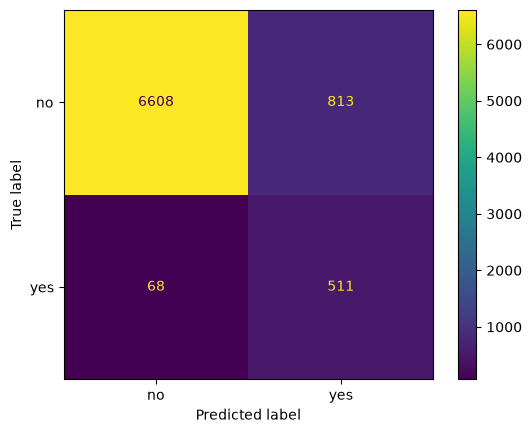

In [22]:
y_pred = final_model.predict(X_test)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["no", "yes"])
plt.savefig(FIGURES_DIR / "confusion_matrix.png", bbox_inches="tight")
plt.show()

In [23]:
pd.DataFrame([call_outcomes(y_test, y_pred)], index=["test set"]).round(1)

,calls made,calls made (% of customers),subscribers found,subscribers found (% of subscribers),subscribers missed,subscribers missed (% of subscribers),unnecessary calls,unnecessary calls (% of non-subscribers),unnecessary calls avoided,unnecessary calls avoided (% of non-subscribers),calls reaching a subscriber (% of calls made)
test set,1324,16.6,511,88.3,68,11.7,813,11.0,6608,89.0,38.6


In [24]:
y_score = final_model.predict_proba(X_test)[:, 1]
gains_table(y_test, y_score).round(1)

,calls made,subscribers found,subscribers found (%)
customers called (%),,,
10,800,412,71.2
20,1600,540,93.3
30,2400,566,97.8
50,4000,579,100.0


- On the test set, the final model scores 0.890 accuracy, 0.386 precision, 0.883 recall, and 0.578 PR-AUC. Accuracy, precision, recall, F1, and ROC-AUC are all within 0.004 of the tuned-threshold row in the final model section. PR-AUC changed the most, rising from 0.553 to 0.578. The final model was trained on all 32,000 training customers, compared with 25,600 in each fold, and the test set has only 579 subscribers, so its PR-AUC can move more than the averaged cross-validation score.
- The final model meets the 81% accuracy target on the test set, at 0.890.
- At the chosen threshold, the model calls 1,324 of the 8,000 test customers (16.6%). It finds 511 of the 579 subscribers (88.3%) and misses 68 (11.7%), and 813 calls are unnecessary (11.0% of non-subscribers). These percentages are within 1 point of the class-weighted row in the decision threshold section (16.4%, 87.6%, 12.4%, and 10.8%), so the threshold carries over to the test customers.
- Calling the top 10% of test customers by score finds 412 of the 579 subscribers (71.2%), about 7 times as many as calling 10% at random. Calling the top 20% finds 540 (93.3%), and the top 50% finds all 579.

## Save the final model

The final model is saved to `models/final_model.joblib` with joblib, which is installed with scikit-learn. The file holds the whole pipeline, including the preprocessing, the tuned XGBoost model, and the decision threshold. `save_model` in `src/models/train.py` also writes `models/final_model.json`, with the model's settings, its cross-validation scores, and the Python, NumPy, scikit-learn, and XGBoost versions. scikit-learn does not support loading a saved model with different versions of scikit-learn or its dependencies, so the versions are needed to load the file later. The cross-validation scores are saved so that a model rebuilt later can be checked against them, as scikit-learn's documentation recommends.

A joblib file can run code when it is loaded, so a saved model should only be loaded from a trusted source. The last cell loads the saved file and checks that it makes the same test set predictions as the model in memory.

In [25]:
model_info = {
    **final_settings,
    "cross-validation scores": final_results["tuned threshold"].round(3).to_dict(),
}
save_model(final_model, model_info)

In [26]:
loaded_model = joblib.load(FINAL_MODEL_PATH)
(loaded_model.predict(X_test) == y_pred).all()

np.True_